# PBMC_3k project - Single-cell RNA-seq preprocessing and clustering 

### Aim
Learn the standard Scanpy workflow on a small, clena benchmark dataset (from raw counts to annotated cell types)

### Data
- 10x Genomics PBMC 3k: ~2,700 peripheral blood mononuclear cells from one healthy donor
- Each row = one cell, each column = one gene (stored in an AnnData)
- No outcome labels => unsupervised, descriptive analysis 

### Workflow
1. QC: remove low-quality cells (few genes, high mitochonridal %) and rarely detected genes
2. Normalise and log-transform
3. Select highly variable genes
4. PCA -> neighbourhood graph
5. UMAP (visualisation) and Leiden clustering
6. FInd marker genes per cluster
7. Annotate clusters as known immune cell types (T cells, B cells, NK cells, monocypte etc)

### Expected output
A UMAP of the cells labelled by cell type with marker genes supporting each label

### Contribution of this step
This pipeline is the foundation for tumour single-cell analysis. The clusters can be compared:
- Composition: how much of each cell type (eg more of a certain T-cell cluster in responder?)
- Expression: how the same cell type behaves across conditions (eg exhausted T cells in tumour vs normal)
- Heterogeneity: vairation within a group (eg tumour subclones, often via inferred copy-number changes (similar to undergrad project))
- TrajectoriesL how cells move between staes (eg active -> exhausted T cells)

Comparison can be between the groups like tumour vs normal, responder vs non-responder, before vs after treatment, one patient vs another but also within the group like subclones 

Findings such as cell-type proportions or state-specific gene signatures can then feed inot patient-level predictive models (Sade-Feldman et al., 2018 used single-cell anlaysis and found TCF7+ CD8 T cells associations with anti-PD-1 response)

In [2]:
# import basic libraries
import scanpy as sc
import anndata as ad # library for handling annotated data matrices

# set figure parameters (dpi for resolution, facecolor for background color)
sc.settings.set_figure_params(dpi=50, facecolor='white')

sc.logging.print_header()

/var/folders/df/6k2bwzwx1t921dqfsfctvxrc0000gn/T/ipykernel_89031/359169487.py:6: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=50, facecolor='white')
/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/IPython/core/formatters.py:1035: RuntimeWarning: Failed to import dependencies for application/vnd.jupyter.widget-view+json representation. (ModuleNotFoundError: No module named 'ipywidgets')
  return method(include=include, exclude=exclude)


Package,Version
scanpy,1.12.4
anndata,0.13.4
Component,Info
Python,"3.12.8 | packaged by Anaconda, Inc. | (main, Dec 11 2024, 10:37:40) [Clang 14.0.6 ]"
OS,macOS-15.3.1-arm64-arm-64bit
CPU,"8/8 logical CPU cores, arm"
GPU,No GPU found
Updated,2026-10-06 15:47
Dependency,Version
numcodecs,0.17.0


### Loading sample dataset 
locally downloaded from https://figshare.com/articles/dataset/NeurIPS_2021_Benchmark_dataset/22716739/1 

In [2]:
# pairing short name for each file
# bone-marrow cells from two different donors at the same site
# a table of how many RNA molecules of each gene were detected in each cell
samples = {
    "s1d1": "data/s1d1_filtered_feature_bc_matrix.h5", # site 1 donor 1
    "s1d3": "data/s1d3_filtered_feature_bc_matrix.h5", # site 1 donor 3
}

adatas = {}

for sample_id, path in samples.items():
    sample_adata = sc.read_10x_h5(path)
    sample_adata.var_names_make_unique() 
    # fixes duplicate gene names since some might have same symbol but they are different genes
    # by putting x-1, x-2 to distinguish (e.g. MT-CO1, MT-CO2, etc.)
    adatas[sample_id] = sample_adata

adata = ad.concat(adatas, label = "sample") # stack s1d1 and s1d3 into one AnnData object with new column "sample"
adata.obs_names_make_unique() # fixes duplicate cell barcodes
# barcode, the unique short DNA sequence can be same even though they are from different patients
# so again, put -1, -2 to distinguish (e.g. AAACCTGAGATG-1 (original), AAACCTGAGATG-1-1, etc.)
# the origianl dataset ends with -1, so the new ones will be -1-1, -1-2, etc.
print(adata.obs["sample"].value_counts())
adata

/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


sample
s1d1    8785
s1d3    8340
Name: count, dtype: int64


/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/var/folders/df/6k2bwzwx1t921dqfsfctvxrc0000gn/T/ipykernel_38012/1114228241.py:18: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = ad.concat(adatas, label = "sample") # stack s1d1 and s1d3 into one AnnData object with new column "sample"


AnnData object with n_obs × n_vars = 17125 × 36601
    obs: 'sample'
    layers: None (.X)

## Quality Control
- empty or broken droplets like few genes or few counts
- dying cells with high mitochondrial percentage (large share of mitochondrial meaning RNA leaked out due to cell's membrane is broken as mitochonrial RNA stays trapped due to the its mitochondrial 
double membrane)
- the proportion of dying cells in patients also important signal but in here removed dying cells inlcude damaged cells during the lab handling process

In [3]:
# add new columns for each gene groups (True, False)

# gene |   mt  | ribo | hb
# RPL13| False | True | False

adata.var["mt"] = adata.var_names.str.startswith("MT-") 
    # annotate the group of mitochondrial genes as "MT"
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL")) 
    # mRNA that code for ribosomal protein (not ribosomal RNA) start with RPS or RPL
    # ribosomal RNA is not polyadenylated, so it is not captured in the 10x library prep
    # and large proportion of ribosomal protein mRNA is not informative for cell type, so sometimes we want to exclude those genes
adata.var["hb"] = adata.var_names.str.startswith("HB[^(P)]")
    # hemoglobin genes starts with HB but the next letter is NOT P
    # to exclude HBP1 which is not hemoglobin gene but a transcription factor
    # high hemoglobin gene expression is a sign of red blood cell contamination, so we want to exclude those cells

In [4]:
# Calculate QC metrics (one value per cell)
    # total_counts - the total number of RNA molecules detected in each cell
    # n_genes_by_counts - how many different genes were detected in each cell
    # total_counts_mt - total number of RNA molecules that are mitochondrial genes (high -> likely damaged cell)
    # pct_counts_mt - percentage of RNA molecules that are mitochondrial genes (high -> likely damaged cell)
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)

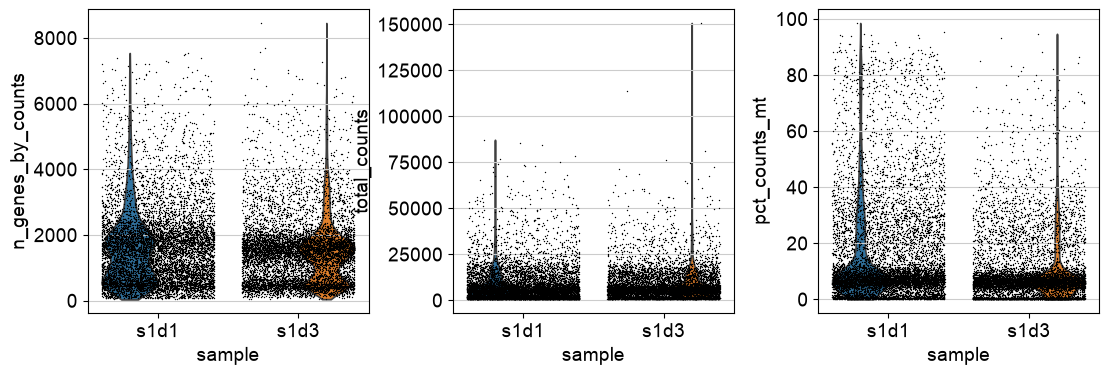

In [5]:
# violin plot of QC metrics
# multiple panels for each metric, jitter to show individual points
# to distinuish between the two patients groupbing by sample added
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], jitter = 0.4, multi_panel = True, groupby = "sample")

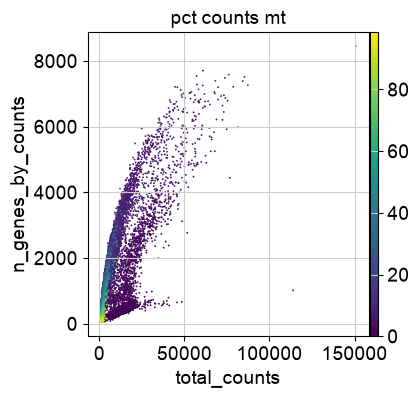

In [6]:
# scatter plot of QC metrics
# colour by percentage of mitochondrial genes
# problematic cells tend to sit bottom left with few counts and few genes with brighter colour
# brighter colour -> higher proportion of mitochondrial genes -> more likely to be dead or dying cells
sc.pl.scatter(adata, x = "total_counts", y = "n_genes_by_counts", color = "pct_counts_mt")

In [7]:
# filtering
sc.pp.filter_cells(adata, min_counts = 100) # remove cells with less than 100 counts
sc.pp.filter_genes(adata, min_counts = 3) # remove genes with less than 3 count

In [8]:
# doublet detection (droplet that accidentally captured two cells instead of one)
# scrublet from Wolock et al., 2019
# scrublet simulates fake doublets by adding together the counts of random pairs or real cells
# Each real cell is then compared in PCA space to its nearest neighbours among real + fake cells 
# using K-nearest neighbour algorithm
# if most of the neighbours are fake doublets -> likely to be a doublet
# this run within the same sample (patient)

sc.pp.scrublet(adata, batch_key = "sample")

In [9]:
# normalization - fixing differences in capture depth between cells
# biologically same cells sometimes have different number of RNA molecules detected due to technical reasons
sc.pp.normalize_total(adata) # rescales to median total counts per cell (default is 1e4)
sc.pp.log1p(adata) # log-transform (log(x +1)) the data to make it more normally distributed

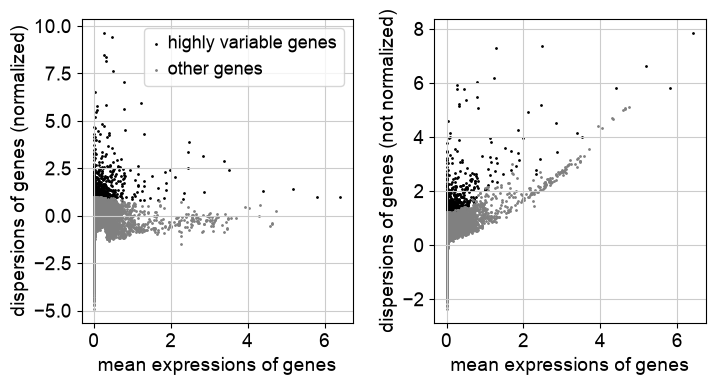

In [10]:
# feature selection
# flag top 2000 highly variable genes (HVGs) 
# batch_key = "sample" to find HVGs within each sample 
sc.pp.highly_variable_genes(adata, n_top_genes = 2000, batch_key = "sample")

# plot the highly variable genes
sc.pl.highly_variable_genes(adata)

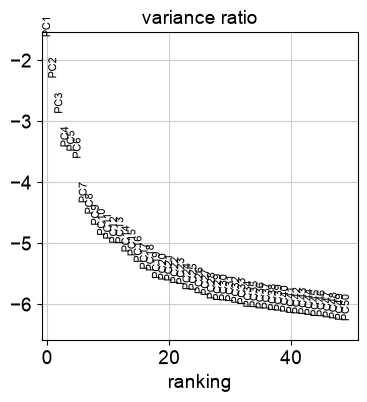

In [ ]:
# dimensionality reduction: PCA
# PCA is a linear dimensionality reduction technique 
# that finds the axes of maximum variance in the data
# replaces 2,000 genes measurements per cell with 50 summary scores (keep the pattern, less noisy)
sc.tl.pca(adata)

# plot shows how much variance is explained by each PC
# x axis: PC number, y axis: log of fraction of total variation that single PC captures
# top PCs tend to separate cell types, while later PCs tend to capture subtypes or activation states within a cell type
# too few pcs miss fine distinction, too many pcs add noise
# when the curve flatten completely around 20-30pcs recommended but tutorial use all 50 and will follow that
sc.pl.pca_variance_ratio(adata, n_pcs=50, log = True) 

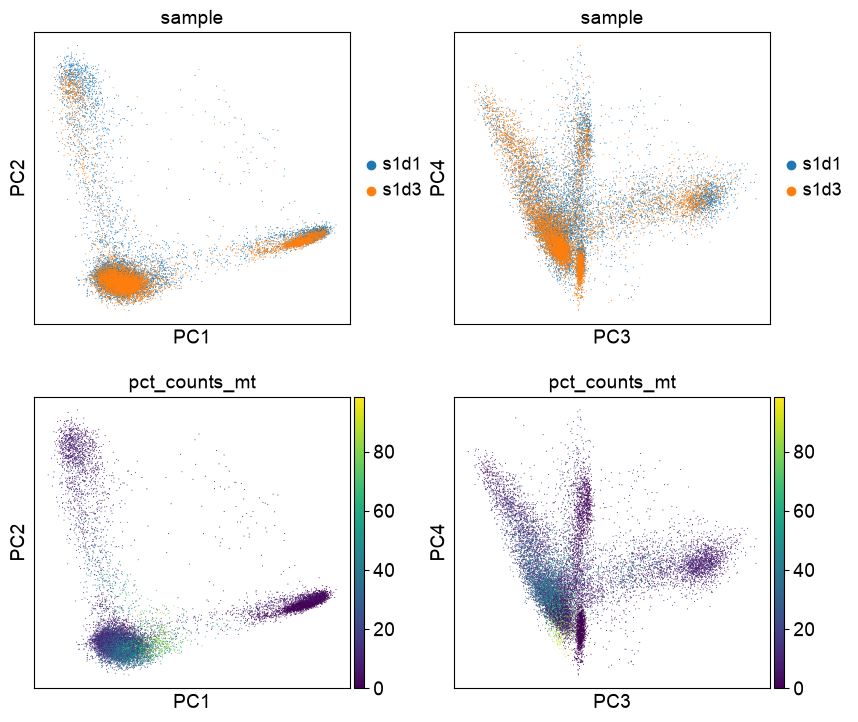

In [ ]:
sc.pl.pca(
    adata, 
    color = ["sample", "sample", "pct_counts_mt", "pct_counts_mt"],
    dimensions = [(0, 1), (2, 3), (0, 1), (2, 3)], # dimensions for which two PCs to use for each panel
    ncols = 2,
    size = 2,
)

# plot 1, pc1 vs pc2 - do the biggest patterns separate the two donors?
# plot 2, pc3 vs pc4 - do the next biggest patterns separate the two donors?
# plot 3, pc1 vs pc2 - do the biggest patterns separate cells with high mitochondrial gene expression?
# plot 4, pc3 vs pc4 - do the next biggest patterns separate cells with high mitochondrial gene expression?

/Users/kimseyeong/Desktop/PBMC 3k/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


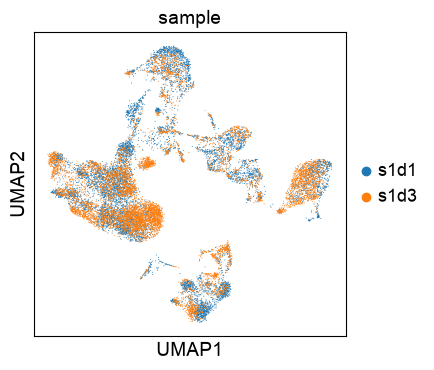

In [ ]:
# Nearest neighbour graph
# foundation of UMAP and clustering
# focus on how far each connected pair is, how strongly each pair is linked
sc.pp.neighbors(adata)

# UMAP
# visualise the 50 dimensional PCA space in 2D while preserving the local structure of the data
# the distance between clusters and cluster size does not reflect how different they are actually
# mainly for structure of the clusters
sc.tl.umap(adata)
sc.pl.umap(adata, color = "sample", size=2)

# this dataset from two different donors but barely batch effect, so no need to do batch correction

## Clustering

Leiden graph-clustering method from Traag et al., 2019
Leiden do not have to specify the number of clusters in advance and can handle any shape and size clusters and Leiden improved connectivities of each clusters from older standard Louvain

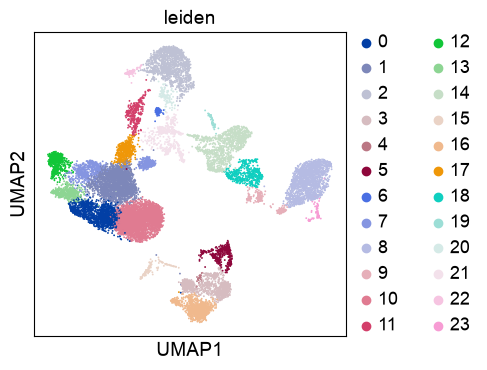

In [14]:
# leiden clustering
sc.tl.leiden(adata, flavor="igraph", n_iterations=2)
sc.pl.umap(adata, color=["leiden"])

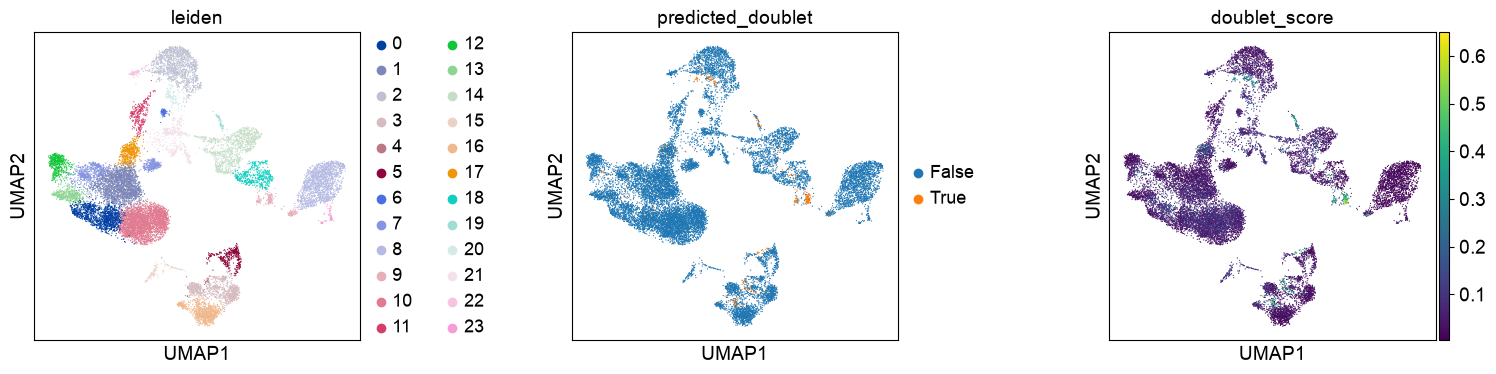

In [ ]:
# checking the doublet distribution across the clusters
sc.pl.umap(
    adata,
    color=["leiden", "predicted_doublet", "doublet_score"],
    wspace=0.5,
    size=3,
)

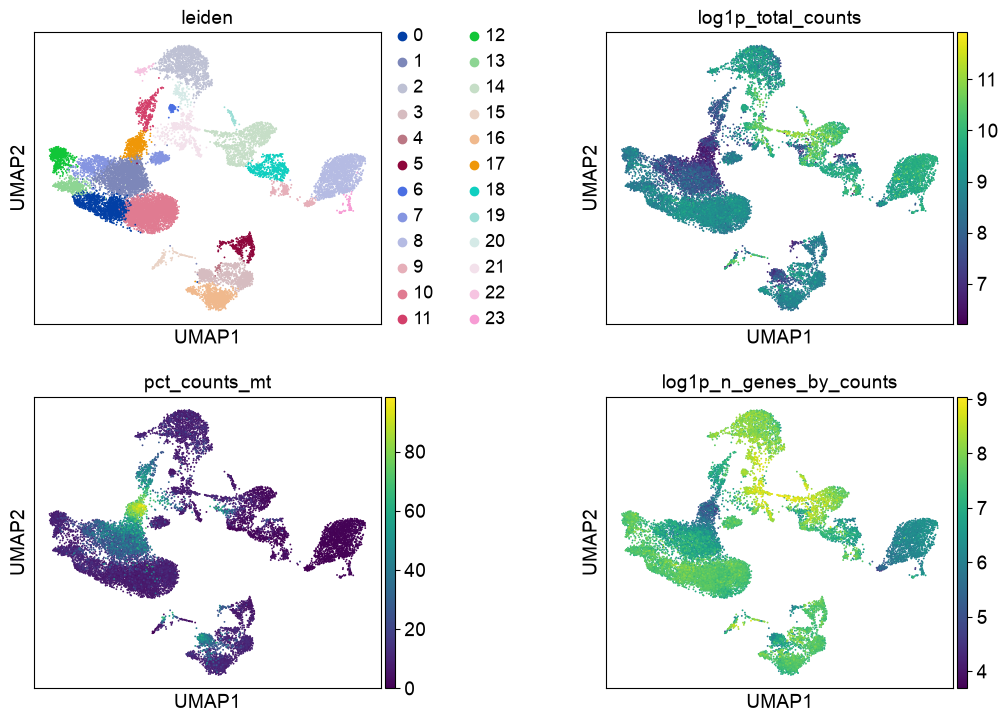

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

# cluster 17 showed high mitochondrial gene expression and low number of genes detected, so likely to be dead or dying cells
# overall data quality is good, so we will not filter out any cells and keep all 2,700 cells for downstream analysis

## Manual cell-type annotation

In [20]:
# Clustering at several resolutions
# lower resolution -> fewer big clusters, higher resolution -> more small clusters
for res in [0.02, 0.5, 2.0]:
    sc.tl.leiden(adata, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph")
    # key_added, add new columns with name leiden _res_0.02, leiden_res_0.50, leiden_res_2.00 for each resolution and make sure they dont overwrite

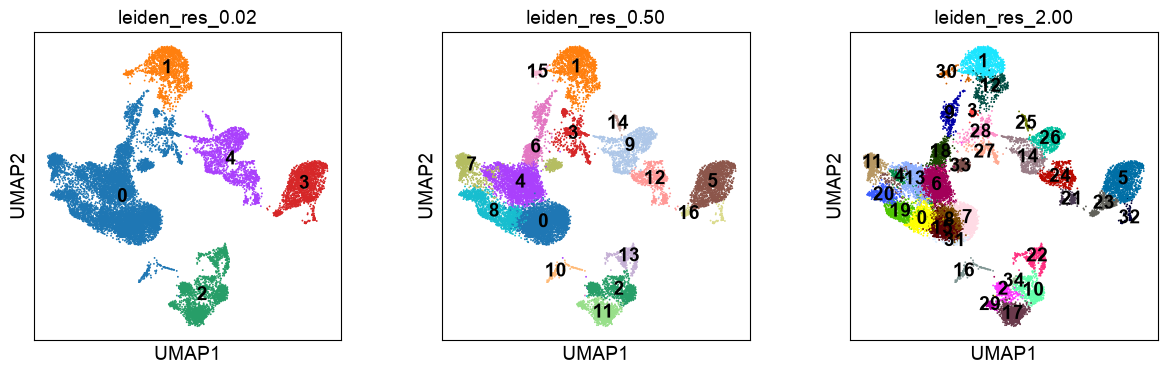

In [19]:
# comparing the resuolutions
sc.pl.umap(adata, color=["leiden_res_0.02", "leiden_res_0.50", "leiden_res_2.00"], legend_loc="on data")

### Marker gene set
A dictionary cell type name: list of genes known to be highly expressed in that cell type based on the literature 

In [21]:
marker_genes = {
    "CD14+ Mono": ["FCN1", "CD14"],
    "CD16+ Mono": ["TCF7L2", "FCGR3A", "LYN"],
    # Note: DMXL2 should be negative
    "cDC2": ["CST3", "COTL1", "LYZ", "DMXL2", "CLEC10A", "FCER1A"],
    "Erythroblast": ["MKI67", "HBA1", "HBB"],
    # Note HBM and GYPA are negative markers
    "Proerythroblast": ["CDK6", "SYNGR1", "HBM", "GYPA"],
    "NK": ["GNLY", "NKG7", "CD247", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"],
    "ILC": ["ID2", "PLCG2", "GNLY", "SYNE1"],
    "Naive CD20+ B": ["MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"],
    # Note IGHD and IGHM are negative markers
    "B cells": [
        "MS4A1",
        "ITGB1",
        "COL4A4",
        "PRDM1",
        "IRF4",
        "PAX5",
        "BCL11A",
        "BLK",
        "IGHD",
        "IGHM",
    ],
    "Plasma cells": ["MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"],
    # Note PAX5 is a negative marker
    "Plasmablast": ["XBP1", "PRDM1", "PAX5"],
    "CD4+ T": ["CD4", "IL7R", "TRBC2"],
    "CD8+ T": ["CD8A", "CD8B", "GZMK", "GZMA", "CCL5", "GZMB", "GZMH", "GZMA"],
    "T naive": ["LEF1", "CCR7", "TCF7"],
    "pDC": ["GZMB", "IL3RA", "COBLL1", "TCF4"],
}

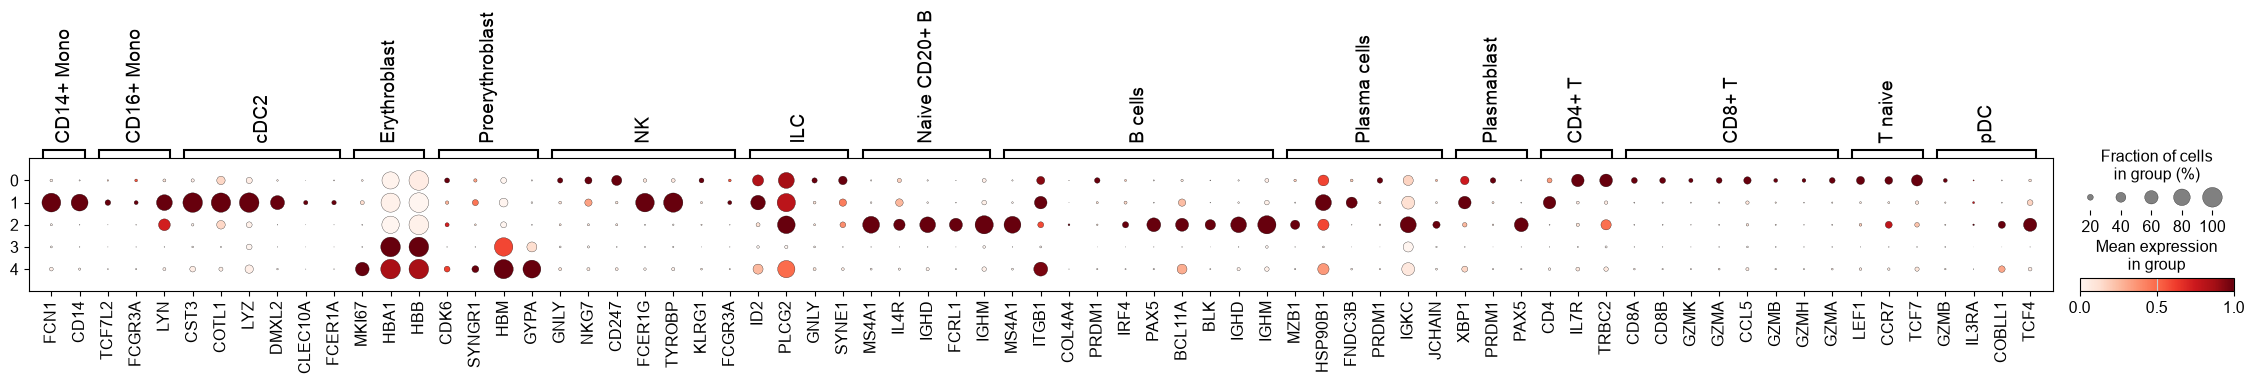

In [ ]:
sc.pl.dotplot(adata, marker_genes, groupby="leiden_res_0.02", standard_scale="var")
# rows represent the clusters based on leiden_res_0.02
# columns represent the marker genes for each cell type
# dot size is the fraction of cells in that cluster expressing the gene
# dot colour is the average expression level in the cells expressing it
# (big dark dot -> most cells in the cluster express the gene strongly)

In [26]:
# use the expression pattern of marker genes we can label the clusters with cell types
adata.obs["cell_type_lvl1"] = adata.obs["leiden_res_0.02"].map(
    {"0": "Lymphocytes", 
     "1": "Monotypes", 
     "2": "B Cells", 
     "3": "Erythroid",
     "4": "Erythroid"})


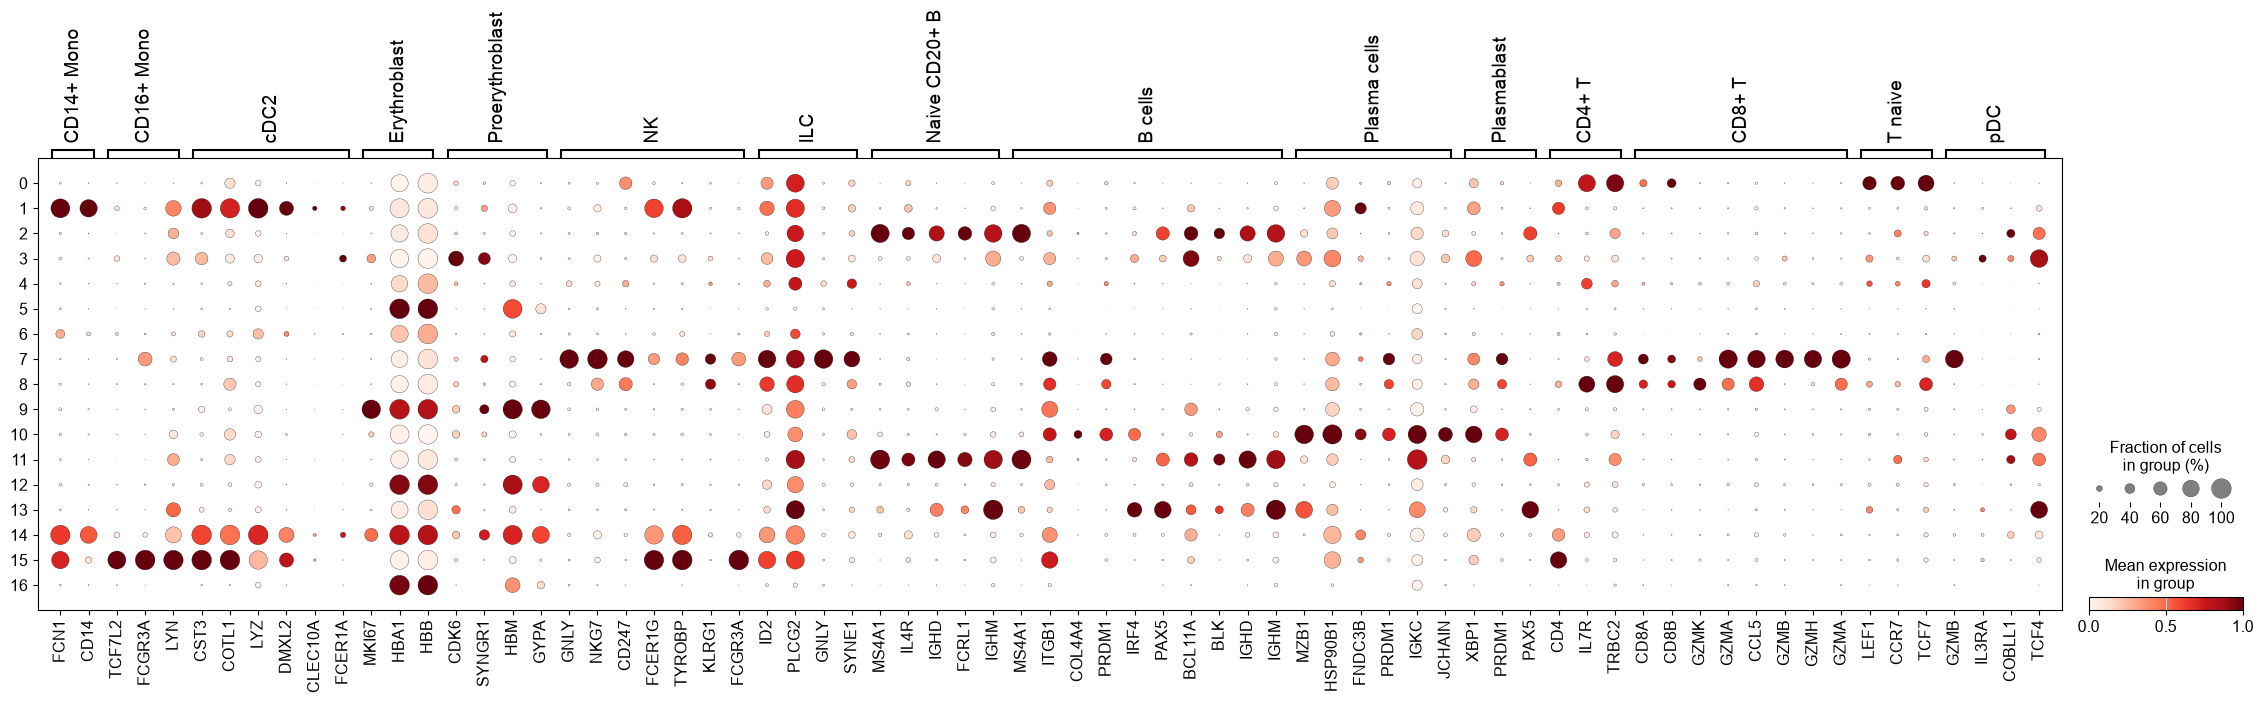

In [27]:
sc.pl.dotplot(adata, marker_genes, groupby="leiden_res_0.50", standard_scale="var")

### Finding marker genes from the data using differential expression
Marker dictionary only checks genes we already know about
Using differential expression finds the genes most distincitively high in that cluster compared to others in each cluster. Wilcoxon statistical test compares the rank of expression values betwee two groups (cells in the chosen cluster vs rest). This method beneficial for clusters that marker list doesn't cover. 

In practice DE suggests candidate genes and we check them against known markers and database. Therefore we use both marker dictionary AND differential expression. 

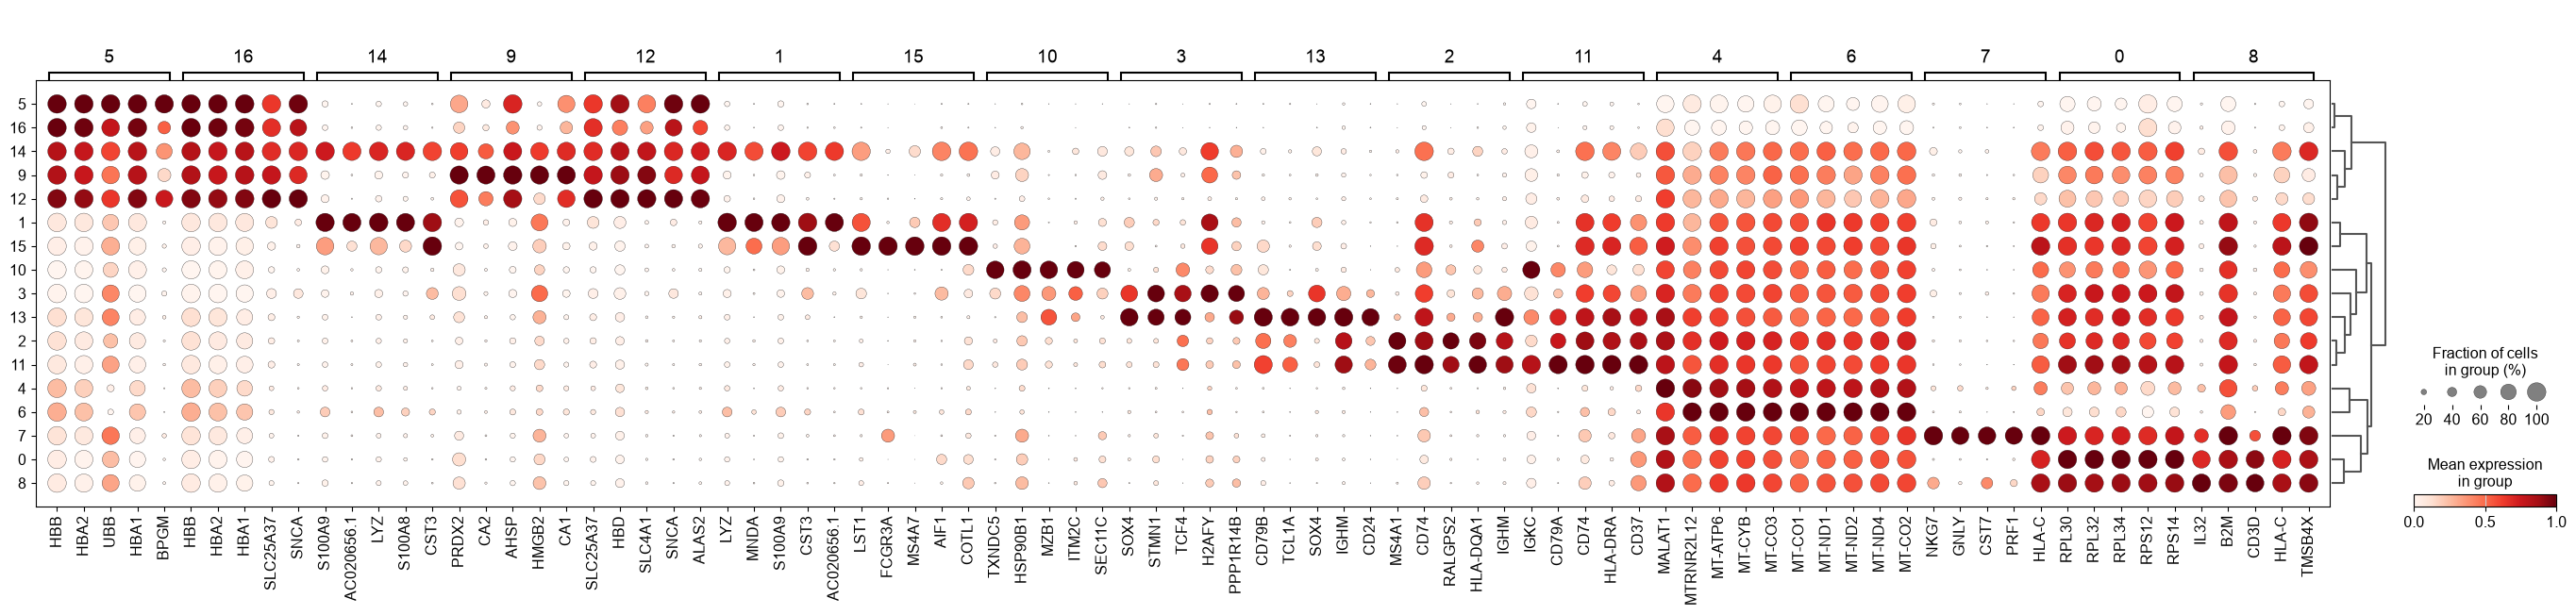

In [31]:
sc.tl.rank_genes_groups(adata, groupby="leiden_res_0.50", method="wilcoxon")
# top 5 genes for each cluster are shown in the dotplot below
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden_res_0.50", standard_scale="var", n_genes=5)

In [ ]:
# clusters results table
sc.get.rank_genes_groups_df(adata, group="7").head(5)

# high scores represent genes that are highly expressed in that cluster compared to other clusters
# logfoldchanges represent relative expression of the gene in that cluster compared to other clusters
# pvals_adj represents p-value corrected for testing thousands of genes, so the smaller the p-value, the more likely that gene is a marker for that cluster
# p values are actually extremely low as the statistical test assumed each cell is independent, 
# but in reality, cells are not independent as they are from the same tissue and same patient, 
# so the p values are not very meaningful (pseudo bulk that gives one value per patientxcell type will be the solution)

,names,scores,logfoldchanges,pvals,pvals_adj
0,NKG7,48.877693,6.905460,0.0,0.0
1,GNLY,44.805744,7.303688,0.0,0.0
2,CST7,44.187511,5.491375,0.0,0.0
3,PRF1,43.150692,5.457508,0.0,0.0
4,HLA-C,42.713898,2.482410,0.0,0.0


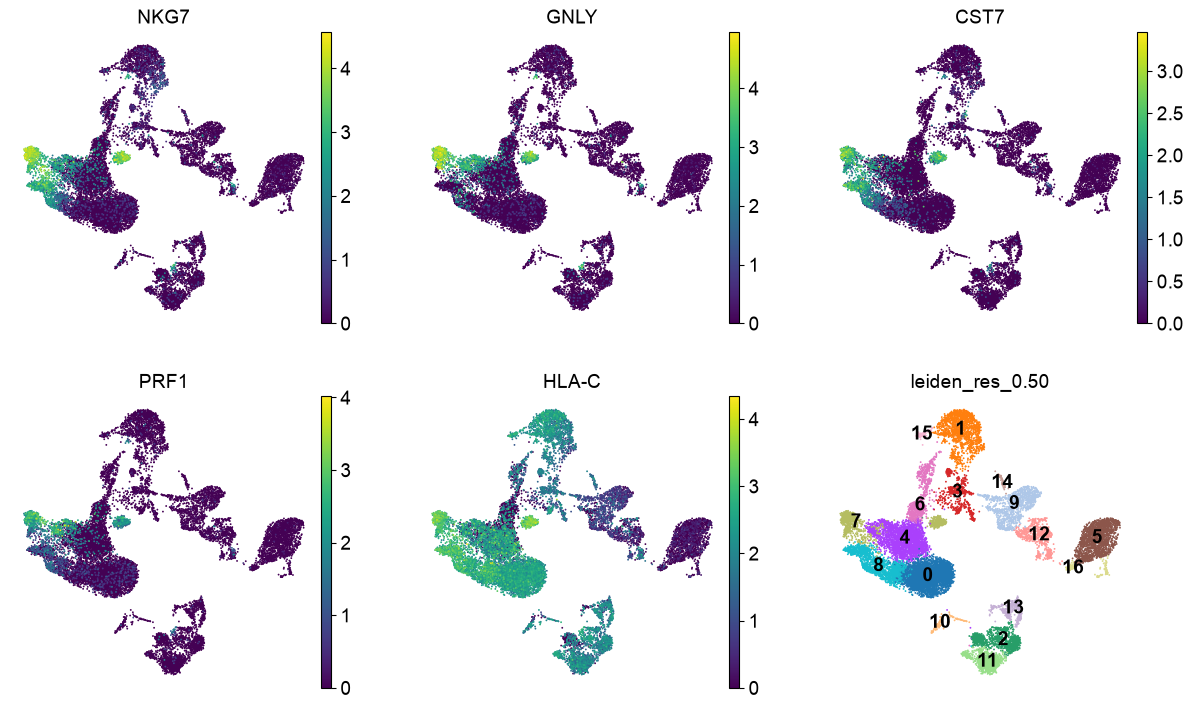

In [33]:
# plotting genes on the UMAP
dc_cluster_genes = sc.get.rank_genes_groups_df(adata, group="7").head(5)["names"]
sc.pl.umap(adata, color=[*dc_cluster_genes, "leiden_res_0.50"], legend_loc="on data", frameon=False, ncols=3)